# Machine Learning-Based Phishing Website Classification and Feature Pattern Clustering

**BIC3213 — Machine Learning for Data Science | Group project**

**Team:** Artemii Bakharev (1002476397), Toh Yi Hui (1002372198), Chatresh Murugesan (1002476386), Wong Chern Hau (1002475565), Teo Sze Hui (1002370812)

**Goal:** Predict whether a website is phishing or legitimate from previously extracted numeric features. Compare supervised learning models, explore feature-based clusters with K-Means, and evaluate three improvement techniques.

**Data:** [UCI PhiUSIIL Phishing URL (Website)](https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset), 235,795 rows (original), 54 features (per UCI), CC BY 4.0.

**IMPORTANT class encoding:** the **original UCI label** is `Label=0 → phishing`, `Label=1 → legitimate`. This notebook creates a new `phishing_target` with `1 → phishing`, `0 → legitimate`, so recall and precision measure phishing detection.

### How to run
1. Download the dataset from the **UCI link above**; click **Download**. Direct ZIP: [PhiUSIIL UCI archive](https://archive.ics.uci.edu/static/public/967/phiusiil%2Bphishing%2Burl%2Bdataset.zip).
2. Put **`PhiUSIIL_Phishing_URL_Dataset.csv`** in the **same folder as this notebook**. Open the notebook in Jupyter/JupyterLab and run all cells. In Colab, upload the CSV to `/content` first.
3. Install dependencies if necessary, then use **Run All**. Outputs appear immediately under the code cells. Tables and charts are also saved in an `outputs_phishing/` directory.

The notebook does **not** visit or scan any listed websites. It uses an already-labelled offline dataset. No results have been pre-computed.

**Checked against your actual CSV:** Its target column is lowercase `label` (not `Label`). The notebook handles either spelling. The dataset is large; if a laptop is slow, change `MAX_ROWS` to `50000` in Setup for a clearly labelled development subset. Leave `MAX_ROWS=None` for the entire dataset.


## 0. Setup

If packages are missing, uncomment and run the install cell below. The analysis uses only standard Python ML libraries.

In [1]:
# Uncomment in Google Colab or a new Jupyter environment if needed:
# %pip install -q pandas numpy scikit-learn matplotlib seaborn joblib

In [2]:
from pathlib import Path
from zipfile import ZipFile
from urllib.request import urlretrieve
import io
import warnings
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectFromModel
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, silhouette_score)

RANDOM_STATE = 42
TEST_SIZE = 0.20
# None = train on every available record; set e.g. 50000 for quicker experimentation.
MAX_ROWS = None
# Keep optimization and clustering inexpensive without reducing the final training data.
TUNING_MAX_ROWS = 12000
CLUSTER_MAX_ROWS = 3500
OUTPUT_DIR = Path('outputs_phishing')
OUTPUT_DIR.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110})
print('Setup complete. Output directory:', OUTPUT_DIR.resolve())

Setup complete. Output directory: C:\Users\Artemii\Downloads\ML Assignment\outputs_phishing


## 1. Load your CSV from the same folder

The loader first looks in the **Jupyter working folder** (normally the folder containing the notebook). If Jupyter started elsewhere, it also checks a few common directories and immediate subfolders. It prints the working directory and the exact CSV path it used. No manual upload code is necessary when the files are next to each other.

In [3]:
CSV_NAME = 'PhiUSIIL_Phishing_URL_Dataset.csv'
ZIP_URL = 'https://archive.ics.uci.edu/static/public/967/phiusiil%2Bphishing%2Burl%2Bdataset.zip'
# When notebook and CSV are together, leave this as None.
# If Jupyter starts in a different folder, you can set an absolute path here.
DATA_FILE = None  # Example: r'C:\Users\YourName\Downloads\Project\PhiUSIIL_Phishing_URL_Dataset.csv'
AUTO_DOWNLOAD_IF_MISSING = False  # Local files first; prevents surprising downloads.

def find_dataset():
    current = Path.cwd()
    print('Jupyter working directory:', current)
    candidates = []
    if DATA_FILE is not None:
        custom = Path(DATA_FILE).expanduser()
        if not custom.is_file():
            raise FileNotFoundError(f'DATA_FILE was set to a missing file: {custom}')
        return custom

    # Same-folder path is searched FIRST. Then look in common notebook launch locations.
    roots = [current, current / 'data', current.parent, Path('/content'), Path('/mnt/data')]
    for root in roots:
        if root.is_dir():
            candidates.extend([root / CSV_NAME, root / 'data' / CSV_NAME])
    # If Jupyter starts one directory above the notebook, find it in a child folder.
    for child in current.iterdir():
        if child.is_dir() and not child.name.startswith('.'):
            candidates.append(child / CSV_NAME)

    seen = set()
    for path in candidates:
        if str(path) not in seen:
            seen.add(str(path))
            if path.is_file():
                return path

    # The UCI website distributes this CSV inside a ZIP, so support that too.
    for root in roots:
        if root.is_dir():
            for path in root.glob('*.zip'):
                if 'phiusiil' in path.name.lower() or '967' in path.name:
                    return path

    if AUTO_DOWNLOAD_IF_MISSING:
        zip_file = current / 'PhiUSIIL_original.zip'
        urlretrieve(ZIP_URL, zip_file)
        return zip_file

    raise FileNotFoundError(
        f'Cannot locate {CSV_NAME}.\n'
        f'Current Jupyter folder: {current}\n'
        'Put the CSV in that folder, OR set DATA_FILE above to its full path.\n'
        f'Files visible in current folder: {[p.name for p in list(current.iterdir())[:20]]}'
    )

csv_path = find_dataset()
print('Reading dataset:', csv_path.resolve())
if csv_path.suffix.lower() == '.zip':
    with ZipFile(csv_path) as archive:
        matches = [n for n in archive.namelist() if Path(n).name.lower() == CSV_NAME.lower()]
        if not matches:
            raise FileNotFoundError(f'No {CSV_NAME} found inside {csv_path}')
        with archive.open(matches[0]) as fp:
            raw = pd.read_csv(fp, low_memory=False)
else:
    raw = pd.read_csv(csv_path, low_memory=False)

print('Original data shape:', raw.shape)
print('Target columns in file:', [c for c in raw.columns if str(c).strip().lower() == 'label'])
print('Column names:', raw.columns.tolist())
display(raw.head(5).drop(columns=[c for c in ['URL','Domain','Title'] if c in raw.columns]))
print('Dataset info:')
raw.info()

Jupyter working directory: c:\Users\Artemii\Downloads\ML Assignment
Reading dataset: C:\Users\Artemii\Downloads\ML Assignment\PhiUSIIL_Phishing_URL_Dataset.csv
Original data shape: (235795, 56)
Target columns in file: ['label']
Column names: ['FILENAME', 'URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields

,FILENAME,URLLength,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,31,24,0,com,100.0,1.000000,0.522907,0.061933,3,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,23,16,0,de,100.0,0.666667,0.032650,0.050207,2,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,29,22,0,uk,100.0,0.866667,0.028555,0.064129,2,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,26,19,0,com,100.0,1.000000,0.522907,0.057606,3,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,33,26,0,org,100.0,1.000000,0.079963,0.059441,3,...,1,0,1,244,15,34,72,1,85,1


Dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscat

## 2. Cleaning and target definition

We remove repeated URL records before splitting, discard identifiers and raw text fields rather than one-hot encoding hundreds of thousands of unique URLs, and use the dataset's pre-extracted numeric characteristics. Preprocessing for models is fitted **only on the training set**.

In [4]:
df = raw.copy()
df.columns = df.columns.astype(str).str.strip()
# Official PhiUSIIL CSV uses lowercase 'label'. Accept either capitalization.
label_columns = [c for c in df.columns if c.lower() == 'label']
if len(label_columns) != 1:
    raise KeyError(f'Expected one label column (label or Label). Found: {label_columns}. Columns: {df.columns.tolist()}')
df = df.rename(columns={label_columns[0]: 'Label'})
print('Label column standardized to: Label')
print('Missing values in original dataset:', int(df.isna().sum().sum()))
print('Duplicate full rows:', int(df.duplicated().sum()))
if 'URL' in df.columns:
    duplicated_url_count = int(df.duplicated(subset='URL').sum())
    print('Repeated URL rows:', duplicated_url_count)
    # Prevent the same URL appearing in both train and test sets.
    # NOTE: if contradictory labels are present, stop rather than arbitrarily choosing one.
    contradictory = df.groupby('URL', dropna=False)['Label'].nunique(dropna=False).gt(1).sum()
    if contradictory:
        raise ValueError(f'{contradictory} URL(s) have conflicting labels. Resolve these before training.')
    df = df.drop_duplicates(subset='URL', keep='first').reset_index(drop=True)
else:
    df = df.drop_duplicates().reset_index(drop=True)

df['Label'] = pd.to_numeric(df['Label'], errors='raise').astype(int)
assert set(df['Label'].unique()) == {0, 1}, 'Unexpected labels: check source dataset.'
df['phishing_target'] = (df['Label'] == 0).astype(int)
text_or_identifier = ['FILENAME', 'URL', 'Domain', 'TLD', 'Title']
feature_candidates = df.drop(columns=['Label', 'phishing_target'] + [c for c in text_or_identifier if c in df.columns])
X_all = feature_candidates.apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan)
# Skip numeric-converted fields with no data (if source schema changes).
X_all = X_all.loc[:, X_all.notna().any(axis=0)].astype('float32')
y_all = df['phishing_target']
if MAX_ROWS is not None and MAX_ROWS < len(df):
    X_all, _, y_all, _ = train_test_split(X_all, y_all, train_size=MAX_ROWS,
                                           stratify=y_all, random_state=RANDOM_STATE)
    print('DEVELOPMENT SUBSAMPLE enabled:', MAX_ROWS)

print(f'Clean dataset: {len(df):,} unique URLs/rows; {X_all.shape[1]} usable numeric features')
print('Supervised dataset size:', X_all.shape)
print('Classes: 0=legitimate, 1=phishing')
summary = y_all.value_counts().sort_index().rename(index={0:'Legitimate',1:'Phishing'}).to_frame('Count')
summary['Percentage'] = (summary['Count'] / len(y_all) * 100).round(2)
display(summary)
summary.to_csv(OUTPUT_DIR / 'class_balance.csv')

Label column standardized to: Label
Missing values in original dataset: 0
Duplicate full rows: 0
Repeated URL rows: 425
Clean dataset: 235,370 unique URLs/rows; 50 usable numeric features
Supervised dataset size: (235370, 50)
Classes: 0=legitimate, 1=phishing


,Count,Percentage
phishing_target,,
Legitimate,134850,57.29
Phishing,100520,42.71


## 3. Exploratory Data Analysis (EDA)

Inspect class balance, descriptive statistics, missing values, feature distributions and correlations. Charts are saved for your report.

,count,mean,std,min,25%,50%,75%,max
URLLength,235370.0,34.546,41.333,13.000,23.000,27.000,34.000,6097.000
DomainLength,235370.0,21.456,9.128,4.000,16.000,20.000,24.000,110.000
IsDomainIP,235370.0,0.003,0.052,0.000,0.000,0.000,0.000,1.000
URLSimilarityIndex,235370.0,78.498,28.948,0.156,57.167,100.000,100.000,100.000
CharContinuationRate,235370.0,0.846,0.216,0.000,0.680,1.000,1.000,1.000
TLDLegitimateProb,235370.0,0.261,0.252,0.000,0.006,0.080,0.523,0.523
URLCharProb,235370.0,0.056,0.011,0.001,0.051,0.058,0.063,0.091
TLDLength,235370.0,2.764,0.600,2.000,2.000,3.000,3.000,13.000
NoOfSubDomain,235370.0,1.165,0.601,0.000,1.000,1.000,1.000,10.000
HasObfuscation,235370.0,0.002,0.045,0.000,0.000,0.000,0.000,1.000


Missing values by feature (nonzero only):


,missing


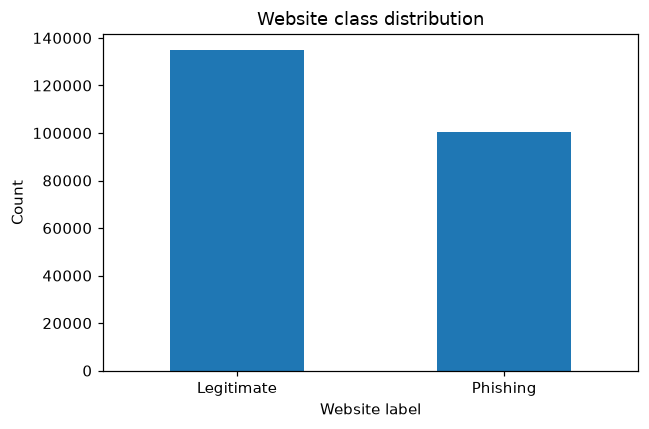

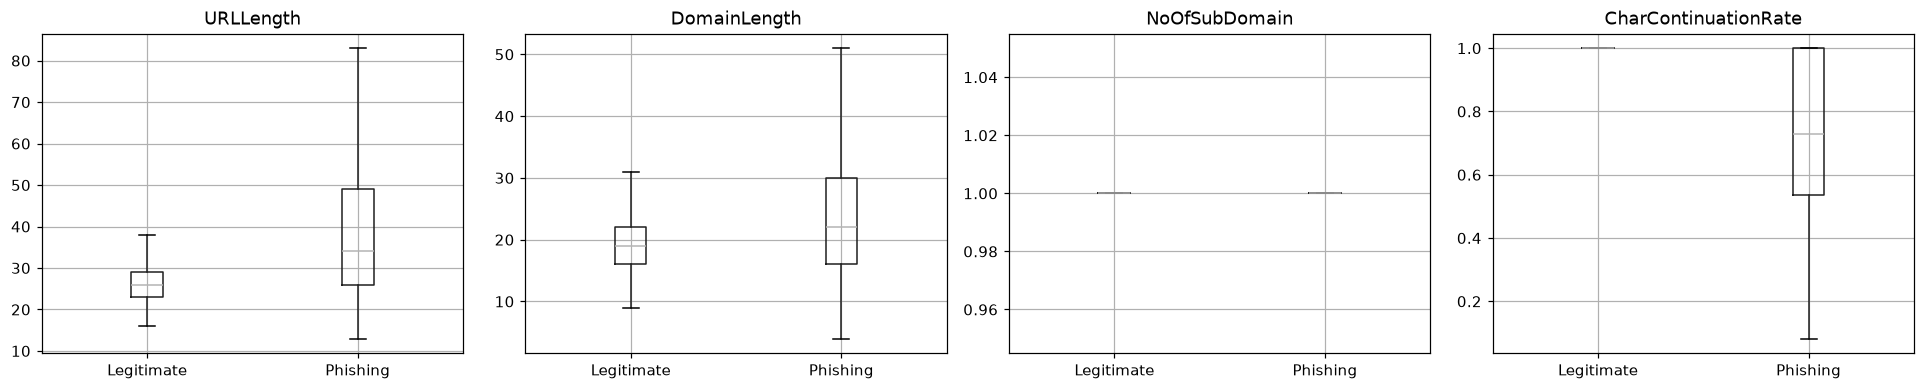

Top 12 |Pearson correlation| with phishing target:


,abs_correlation
URLSimilarityIndex,0.860342
HasSocialNet,0.783882
HasCopyrightInfo,0.743197
HasDescription,0.690011
IsHTTPS,0.610253
DomainTitleMatchScore,0.584204
HasSubmitButton,0.578816
IsResponsive,0.548977
URLTitleMatchScore,0.538844
SpacialCharRatioInURL,0.533003


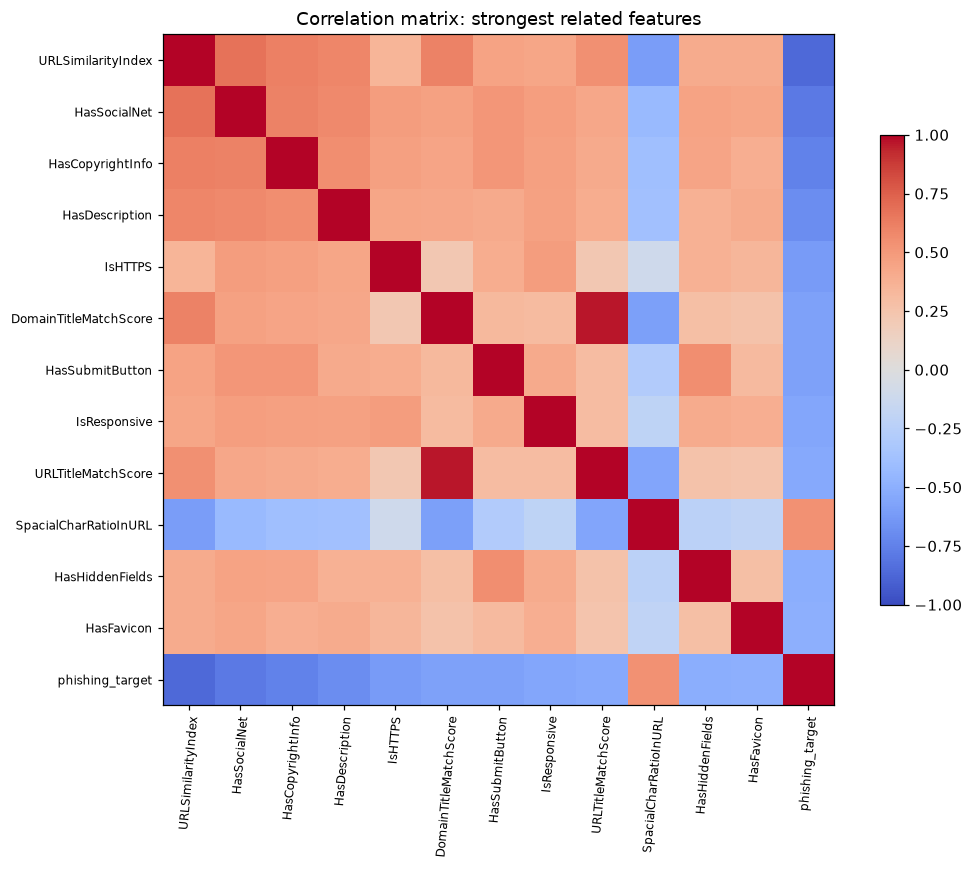

In [5]:
display(X_all.describe().T.round(3).head(20))
missing = X_all.isna().sum().sort_values(ascending=False)
print('Missing values by feature (nonzero only):')
display(missing[missing > 0].to_frame('missing'))

fig, ax = plt.subplots(figsize=(6, 4))
y_all.map({0:'Legitimate',1:'Phishing'}).value_counts().reindex(['Legitimate','Phishing']).plot(kind='bar', ax=ax, rot=0)
ax.set(title='Website class distribution', xlabel='Website label', ylabel='Count')
fig.tight_layout(); fig.savefig(OUTPUT_DIR/'01_class_distribution.png', dpi=160); plt.show()

plot_features = [c for c in ['URLLength','DomainLength','NoOfSubDomain','CharContinuationRate'] if c in X_all.columns]
if not plot_features:
    plot_features = X_all.columns[:4].tolist()
eda_rows = X_all.sample(n=min(10000, len(X_all)), random_state=RANDOM_STATE).copy()
eda_rows['Type'] = y_all.loc[eda_rows.index].map({0:'Legitimate',1:'Phishing'})
fig, axes = plt.subplots(1, len(plot_features), figsize=(4.4*len(plot_features), 3.8))
axes = np.atleast_1d(axes)
for ax, name in zip(axes, plot_features):
    eda_rows.boxplot(column=name, by='Type', ax=ax, showfliers=False)
    ax.figure.suptitle('')
    ax.set_title(name); ax.set_xlabel('')
fig.tight_layout(); fig.savefig(OUTPUT_DIR/'02_feature_boxplots.png', dpi=160); plt.show()

# Absolute feature/target correlation is descriptive EDA only, not supervised feature selection.
correlations = X_all.corrwith(y_all).abs().sort_values(ascending=False).dropna()
print('Top 12 |Pearson correlation| with phishing target:')
display(correlations.head(12).rename('abs_correlation').to_frame())
selected_eda = correlations.head(min(12,len(correlations))).index.tolist()
if selected_eda:
    corr_plot = pd.concat([X_all[selected_eda], y_all.rename('phishing_target')], axis=1).corr()
    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(corr_plot.to_numpy(), cmap='coolwarm', vmin=-1, vmax=1)
    ax.set_xticks(np.arange(len(corr_plot.columns)), corr_plot.columns, rotation=85, fontsize=8)
    ax.set_yticks(np.arange(len(corr_plot.index)), corr_plot.index, fontsize=8)
    fig.colorbar(im, ax=ax, shrink=.7)
    ax.set_title('Correlation matrix: strongest related features')
    fig.tight_layout(); fig.savefig(OUTPUT_DIR/'03_correlation_heatmap.png', dpi=160); plt.show()

## 4. Train/test split and baseline supervised models

**Paper method reference:** Alenezi & Alenezi (2026), [*Phishing URL Classification in Cybersecurity Education*](https://doi.org/10.3390/info17050401). Its baseline compares classical models on PhiUSIIL with a stratified split and model validation. Here we implement **Random Forest and Logistic Regression** on a held-out 20% split, keeping transforms inside training-only pipelines.

We intentionally exclude raw URL/domain/title/TLD strings for a compact reproducible notebook. This is a **methodological reproduction/extension**, not a bit-for-bit replica of the paper.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_all)
print('Train:', X_train.shape, 'Test:', X_test.shape)

def rf_pipeline(**model_kwargs):
    args = dict(n_estimators=80, random_state=RANDOM_STATE, n_jobs=-1, min_samples_leaf=2)
    args.update(model_kwargs)
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', RandomForestClassifier(**args)),
    ])

def lr_pipeline(C=1.0):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(C=C, max_iter=1200, random_state=RANDOM_STATE)),
    ])

def evaluate_model(name, fitted_model, X_evaluate=X_test, y_evaluate=y_test):
    start = time.perf_counter()
    pred = fitted_model.predict(X_evaluate)
    prob = fitted_model.predict_proba(X_evaluate)[:,1]
    runtime = time.perf_counter() - start
    tn, fp, fn, tp = confusion_matrix(y_evaluate, pred, labels=[0,1]).ravel()
    row = {
        'Model': name,
        'Accuracy': accuracy_score(y_evaluate, pred),
        'Precision_phishing': precision_score(y_evaluate, pred, zero_division=0),
        'Recall_phishing': recall_score(y_evaluate, pred, zero_division=0),
        'F1_phishing': f1_score(y_evaluate, pred, zero_division=0),
        'ROC_AUC_phishing': roc_auc_score(y_evaluate, prob),
        'Specificity_legitimate': tn/(tn+fp) if (tn+fp) else np.nan,
        'False_positive': fp, 'False_negative': fn,
        'Predict_seconds': round(runtime, 3),
    }
    return row, pred, prob

models = {}
results = []
for name, model in [('Random Forest (baseline)', rf_pipeline()),
                    ('Logistic Regression (baseline)', lr_pipeline())]:
    print('Training:', name)
    model.fit(X_train, y_train)
    models[name] = model
    result, predictions, probabilities = evaluate_model(name, model)
    results.append(result)
    print(name, ': Accuracy =', round(result['Accuracy'], 4),
          ' F1(phishing) =', round(result['F1_phishing'], 4))

baseline_results = pd.DataFrame(results).set_index('Model')
display(baseline_results.round(4))
baseline_results.to_csv(OUTPUT_DIR/'04_baseline_results.csv')

Train: (188296, 50) Test: (47074, 50)
Training: Random Forest (baseline)
Random Forest (baseline) : Accuracy = 1.0  F1(phishing) = 1.0
Training: Logistic Regression (baseline)
Logistic Regression (baseline) : Accuracy = 0.9998  F1(phishing) = 0.9998


,Accuracy,Precision_phishing,Recall_phishing,F1_phishing,ROC_AUC_phishing,Specificity_legitimate,False_positive,False_negative,Predict_seconds
Model,,,,,,,,,
Random Forest (baseline),1.0000,1.0,0.9999,1.0000,1.0,1.0,0,2,0.129
Logistic Regression (baseline),0.9998,1.0,0.9996,0.9998,1.0,1.0,0,8,0.049



 Random Forest (baseline)
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     26970
    Phishing       1.00      1.00      1.00     20104

    accuracy                           1.00     47074
   macro avg       1.00      1.00      1.00     47074
weighted avg       1.00      1.00      1.00     47074



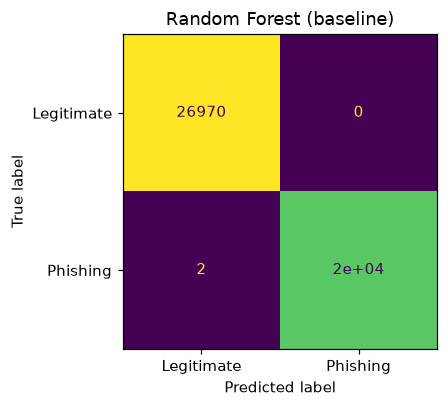


 Logistic Regression (baseline)
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     26970
    Phishing       1.00      1.00      1.00     20104

    accuracy                           1.00     47074
   macro avg       1.00      1.00      1.00     47074
weighted avg       1.00      1.00      1.00     47074



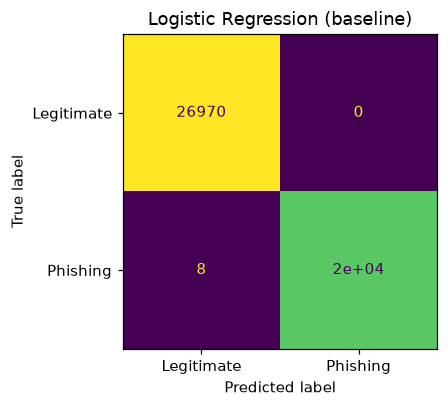

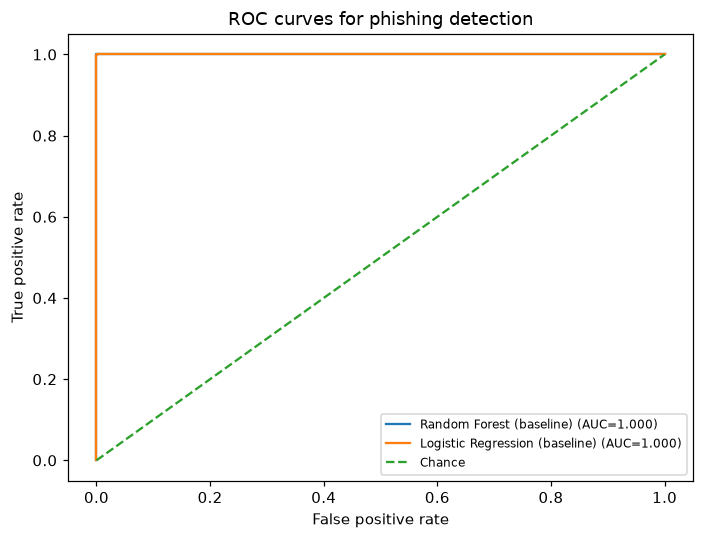

In [7]:
for name in ['Random Forest (baseline)', 'Logistic Regression (baseline)']:
    model = models[name]
    row, pred, prob = evaluate_model(name, model)
    print('\n', name)
    print(classification_report(y_test, pred, labels=[0,1], target_names=['Legitimate','Phishing'], zero_division=0))
    fig, ax = plt.subplots(figsize=(4.6,3.8))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[0,1],
        display_labels=['Legitimate','Phishing'], ax=ax, colorbar=False)
    ax.set_title(name)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR/('05_cm_' + name.split(' (')[0].replace(' ','_') + '.png'), dpi=160)
    plt.show()

fig, ax = plt.subplots(figsize=(6.5,5))
for name, model in models.items():
    probabilities = model.predict_proba(X_test)[:,1]
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, probabilities)
    ax.plot(false_positive_rate, true_positive_rate,
            label=f'{name} (AUC={roc_auc_score(y_test,probabilities):.3f})')
ax.plot([0,1],[0,1],'--',label='Chance')
ax.set(xlabel='False positive rate', ylabel='True positive rate', title='ROC curves for phishing detection')
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUTPUT_DIR/'06_roc_curves.png',dpi=160); plt.show()

## 5. Unsupervised learning: K-Means feature-pattern clustering

K-Means receives **only numeric website characteristics**, not the class label. It groups sites with similar measured properties. After fitting, we inspect the proportion of known phishing records per cluster for interpretation. Do not assume a cluster is a proven attack type.

Clustering features: ['URLLength', 'DomainLength', 'NoOfSubDomain', 'TLDLength', 'CharContinuationRate', 'URLCharProb', 'NoOfLettersInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfOtherSpecialCharsInURL', 'IsHTTPS']


,K,Inertia,Silhouette
0,2,29753.2285,0.8292
1,3,23941.9609,0.3488
2,4,21085.3789,0.3140
3,5,18511.6602,0.3266
4,6,16545.9609,0.3233


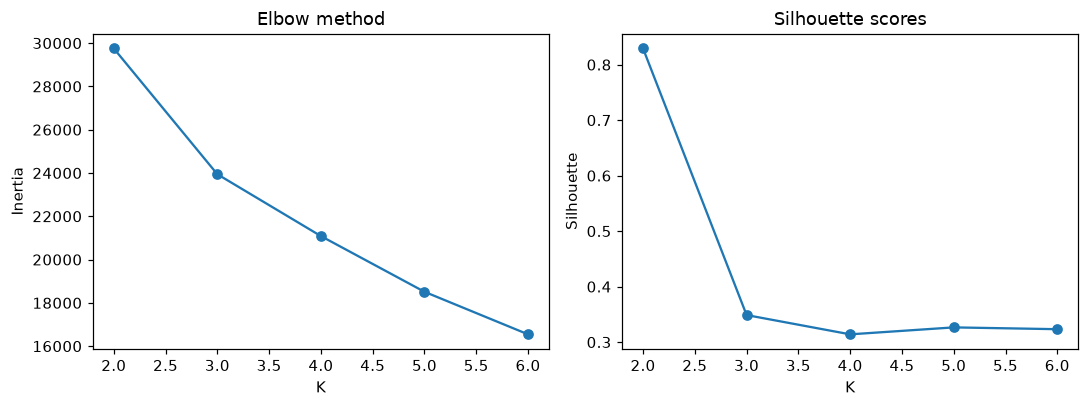

Best K by silhouette: 2


,n_websites,phishing_rate,phishing_percent
Cluster,,,
0,3473,0.41,41.03
1,27,1.00,100.00


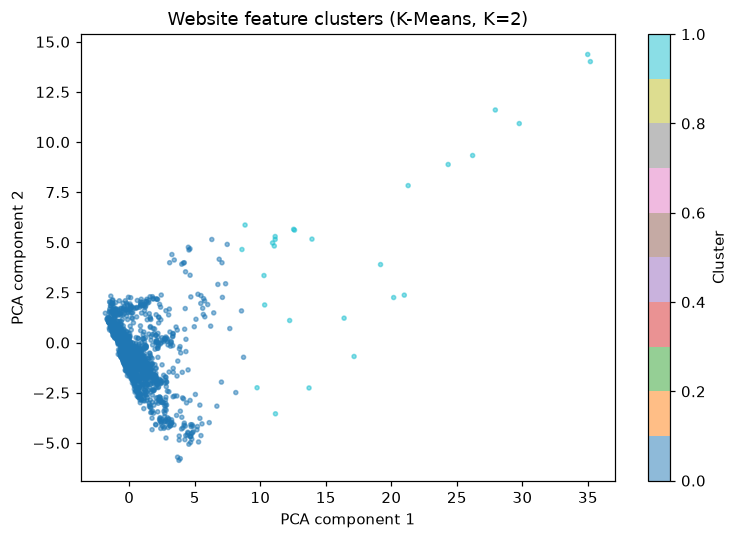

,URLLength,DomainLength,NoOfSubDomain,TLDLength,CharContinuationRate,URLCharProb,NoOfLettersInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfOtherSpecialCharsInURL,IsHTTPS
Cluster,,,,,,,,,,,
0,-0.06,-0.01,-0.01,-0.00,0.01,0.01,-0.06,-0.07,-0.06,-0.05,0.00
1,8.04,0.92,1.51,0.15,-1.55,-1.48,7.62,8.96,7.96,6.88,-0.29


In [8]:
# Domain-independent, easily interpretable structural characteristics where present.
preferred = ['URLLength', 'DomainLength', 'NoOfSubDomain', 'TLDLength',
             'CharContinuationRate', 'URLCharProb', 'NoOfLettersInURL',
             'NoOfDigitsInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL',
             'NoOfOtherSpecialCharsInURL', 'IsHTTPS']
cluster_features = [c for c in preferred if c in X_train.columns]
if len(cluster_features) < 3:
    cluster_features = X_train.columns[:min(12, X_train.shape[1])].tolist()
print('Clustering features:', cluster_features)

clust_idx = X_train.sample(n=min(CLUSTER_MAX_ROWS,len(X_train)), random_state=RANDOM_STATE).index
X_cluster = X_train.loc[clust_idx, cluster_features].copy()
y_cluster_for_interpretation = y_train.loc[clust_idx].copy()
cluster_imp = SimpleImputer(strategy='median')
cluster_scale = StandardScaler()
Z = cluster_scale.fit_transform(cluster_imp.fit_transform(X_cluster))

ks = range(2,7)
inertia, silhouettes = [], []
for k in ks:
    test_km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    assigned = test_km.fit_predict(Z)
    inertia.append(test_km.inertia_)
    silhouettes.append(silhouette_score(Z, assigned, sample_size=min(1500,len(Z)), random_state=RANDOM_STATE))
cluster_scores = pd.DataFrame({'K':list(ks), 'Inertia':inertia, 'Silhouette':silhouettes})
display(cluster_scores.round(4))
cluster_scores.to_csv(OUTPUT_DIR/'07_clustering_k_selection.csv', index=False)
fig, axes = plt.subplots(1,2,figsize=(10,3.8))
axes[0].plot(cluster_scores['K'],cluster_scores['Inertia'],'o-'); axes[0].set(title='Elbow method',xlabel='K',ylabel='Inertia')
axes[1].plot(cluster_scores['K'],cluster_scores['Silhouette'],'o-'); axes[1].set(title='Silhouette scores',xlabel='K',ylabel='Silhouette')
fig.tight_layout();fig.savefig(OUTPUT_DIR/'08_k_selection.png',dpi=160);plt.show()

best_k = int(cluster_scores.loc[cluster_scores['Silhouette'].idxmax(),'K'])
print('Best K by silhouette:', best_k)
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
cluster_ids = kmeans.fit_predict(Z)
cluster_table = pd.DataFrame({'Cluster':cluster_ids, 'Phishing':y_cluster_for_interpretation.to_numpy()})
profile = cluster_table.groupby('Cluster').agg(n_websites=('Phishing','size'),phishing_rate=('Phishing','mean'))
profile['phishing_percent'] = 100*profile['phishing_rate']
display(profile.round(2))
profile.to_csv(OUTPUT_DIR/'09_cluster_profiles.csv')

proj = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Z)
fig, ax = plt.subplots(figsize=(7,5))
sc=ax.scatter(proj[:,0],proj[:,1],c=cluster_ids,s=7,alpha=.5,cmap='tab10')
ax.set(title=f'Website feature clusters (K-Means, K={best_k})', xlabel='PCA component 1',ylabel='PCA component 2')
fig.colorbar(sc,ax=ax,label='Cluster')
fig.tight_layout();fig.savefig(OUTPUT_DIR/'10_cluster_pca.png',dpi=160);plt.show()

# Explain high/low standardized characteristics within each cluster.
cluster_feature_profile = pd.DataFrame(Z, columns=cluster_features).assign(Cluster=cluster_ids).groupby('Cluster').mean()
display(cluster_feature_profile.round(2))
cluster_feature_profile.to_csv(OUTPUT_DIR/'11_cluster_feature_profiles.csv')

## 6. Three improvement techniques

**(1) Cross-validation:** estimate baseline RF performance across stratified folds using training data only.

**(2) Hyperparameter tuning:** choose RF parameters using `RandomizedSearchCV` with stratified 3-fold CV.

**(3) Feature selection:** train a second RF using the top 15 features ranked on training data only. We compare all versions on the same held-out test set.

A training-only subset is used for the tuning search to keep coursework runtime practical. The selected model is subsequently retrained on the **full training set**.

In [9]:
# Restrict repeated CV computations to a reproducible subset of training data.
if len(X_train) > TUNING_MAX_ROWS:
    Xtune, _, ytune, _ = train_test_split(X_train, y_train,
        train_size=TUNING_MAX_ROWS, stratify=y_train, random_state=RANDOM_STATE)
else:
    Xtune, ytune = X_train, y_train
print('CV/tuning data:', Xtune.shape)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(rf_pipeline(n_estimators=50, max_depth=16), Xtune, ytune,
                           cv=cv, scoring='f1', n_jobs=1)
print('3-fold cross-validation F1 (phishing):', np.round(cv_scores,4))
print('CV mean:', round(float(cv_scores.mean()),4), 'CV std:', round(float(cv_scores.std()),4))
pd.DataFrame({'fold': [1,2,3], 'F1_phishing':cv_scores}).to_csv(OUTPUT_DIR/'12_cross_validation.csv',index=False)

CV/tuning data: (12000, 50)
3-fold cross-validation F1 (phishing): [1.     1.     0.9994]
CV mean: 0.9998 CV std: 0.0003


In [10]:
# A modest search space keeps the notebook tractable on an ordinary laptop.
search = RandomizedSearchCV(
    estimator=rf_pipeline(),
    param_distributions={
        'classifier__n_estimators':[60,90,120],
        'classifier__max_depth':[12,20,None],
        'classifier__min_samples_leaf':[1,2,4],
        'classifier__max_features':['sqrt', 0.7],
    },
    n_iter=5, cv=cv, scoring='f1', random_state=RANDOM_STATE,
    n_jobs=1, verbose=0, refit=True
)
search.fit(Xtune, ytune)
print('Best parameters:', search.best_params_)
print('Best CV F1:', round(float(search.best_score_),4))
pd.DataFrame(search.cv_results_).sort_values('rank_test_score').to_csv(OUTPUT_DIR/'13_rf_tuning.csv',index=False)

# Refit optimal pipeline with *all* available training records.
tuned_model = rf_pipeline(**{k.replace('classifier__',''):v for k,v in search.best_params_.items()})
tuned_model.fit(X_train, y_train)
models['Random Forest (tuned)'] = tuned_model
results.append(evaluate_model('Random Forest (tuned)',tuned_model)[0])
print('Held-out test performance:')
display(pd.DataFrame([results[-1]]).round(4))

Best parameters: {'classifier__n_estimators': 90, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 0.7, 'classifier__max_depth': None}
Best CV F1: 0.9999
Held-out test performance:


,Model,Accuracy,Precision_phishing,Recall_phishing,F1_phishing,ROC_AUC_phishing,Specificity_legitimate,False_positive,False_negative,Predict_seconds
0,Random Forest (tuned),1.0,1.0,1.0,1.0,1.0,1.0,0,0,0.145


Top features: ['URLSimilarityIndex', 'NoOfExternalRef', 'LineOfCode', 'NoOfSelfRef', 'NoOfImage', 'NoOfJS', 'NoOfCSS', 'HasDescription', 'IsHTTPS', 'HasSocialNet', 'HasCopyrightInfo', 'LargestLineLength', 'NoOfDegitsInURL', 'NoOfOtherSpecialCharsInURL', 'IsResponsive']


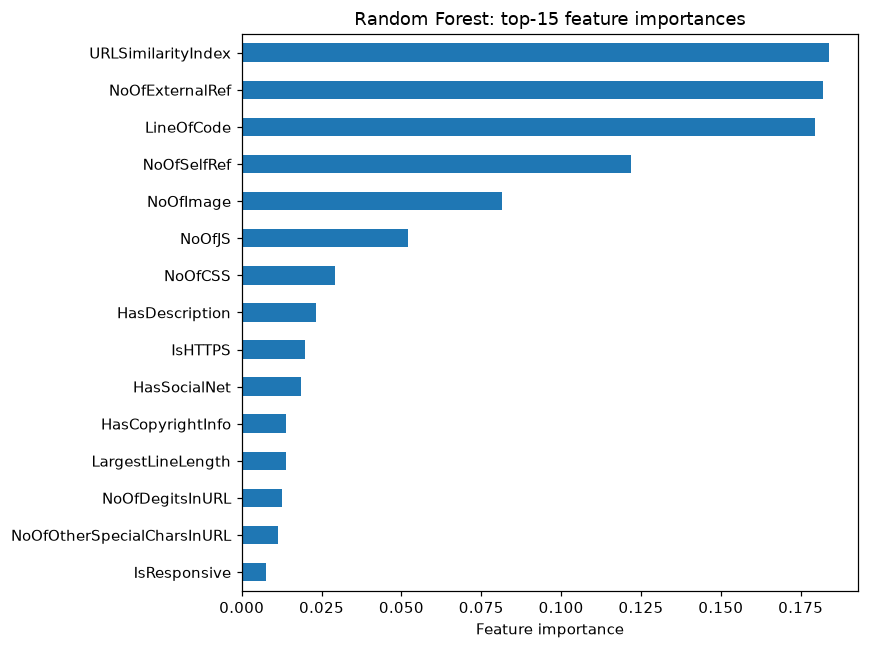

Test results after selecting features:


,Model,Accuracy,Precision_phishing,Recall_phishing,F1_phishing,ROC_AUC_phishing,Specificity_legitimate,False_positive,False_negative,Predict_seconds
0,Random Forest (top 15 features),1.0,1.0,1.0,1.0,1.0,1.0,0,0,0.095


In [11]:
# Select top 15 using importance scores from the baseline RF fitted on training data.
base_rf = models['Random Forest (baseline)'].named_steps['classifier']
importance = pd.Series(base_rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
selected_features = importance.head(min(15, len(importance))).index.tolist()
print('Top features:', selected_features)

fig, ax = plt.subplots(figsize=(8,6))
importance.head(15).sort_values().plot(kind='barh',ax=ax)
ax.set(title='Random Forest: top-15 feature importances',xlabel='Feature importance')
fig.tight_layout();fig.savefig(OUTPUT_DIR/'14_feature_importances.png',dpi=160);plt.show()

# Feature selection is based only on training-set RF, never the test set.
selected_model = rf_pipeline(**{k.replace('classifier__',''):v for k,v in search.best_params_.items()})
selected_model.fit(X_train[selected_features], y_train)
models['Random Forest (top 15 features)'] = selected_model
results.append(evaluate_model('Random Forest (top 15 features)', selected_model,
                              X_test[selected_features],y_test)[0])

print('Test results after selecting features:')
display(pd.DataFrame([results[-1]]).round(4))
importance.to_csv(OUTPUT_DIR/'15_all_feature_importances.csv',header=['importance'])

## 7. Final comparison with the published paper

The 2026 paper reports **RF accuracy 93.33% and F1 93.75%**. This notebook uses its **dataset and broad evaluation approach**, but not necessarily identical preprocessing, feature encoding, software, hyperparameters or test records. Therefore, the published numbers are a **reference, not a direct matched replication benchmark**. You should explain numerical differences rather than claim an exact reproduction.

**Note:** Your downloaded CSV uses lowercase `label`. The notebook normalizes this safely, keeping the official label meaning: `0=phishing`, `1=legitimate`.


,Accuracy,Precision_phishing,Recall_phishing,F1_phishing,ROC_AUC_phishing,Specificity_legitimate,False_positive,False_negative,Predict_seconds
Model,,,,,,,,,
Random Forest (baseline),1.0000,1.0,0.9999,1.0000,1.0,1.0,0,2,0.129
Logistic Regression (baseline),0.9998,1.0,0.9996,0.9998,1.0,1.0,0,8,0.049
Random Forest (tuned),1.0000,1.0,1.0000,1.0000,1.0,1.0,0,0,0.145
Random Forest (top 15 features),1.0000,1.0,1.0000,1.0000,1.0,1.0,0,0,0.095


,Source,Model,Accuracy,F1_phishing,Comparability
0,"Alenezi & Alenezi (2026), Information 17(5), 401",Random Forest,0.9333,0.9375,Reference only: different experimental setup /...


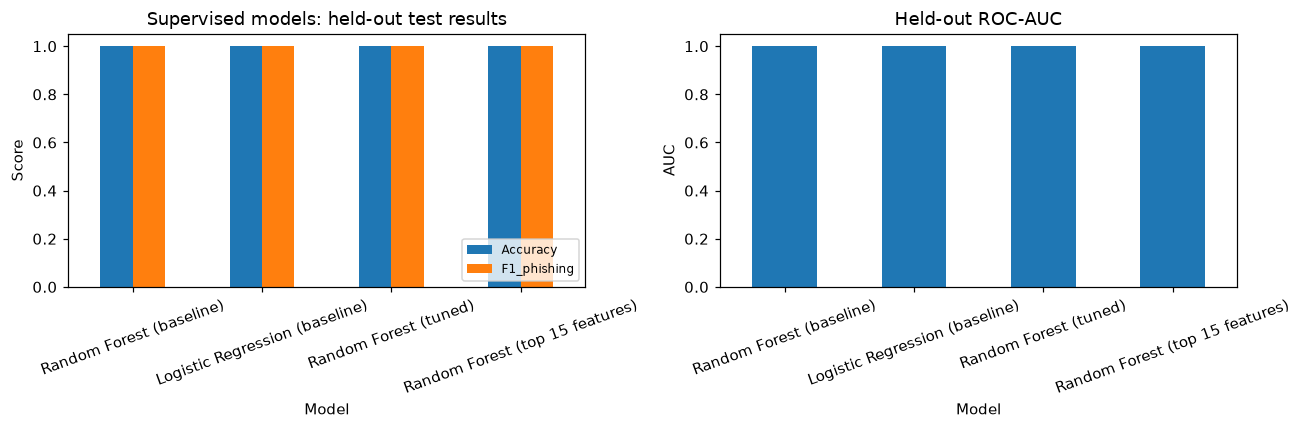

Paper reference (RF): 0.9333 accuracy; 0.9375 F1. Different protocols: interpret cautiously.
Best test F1 in this notebook: Random Forest (tuned)
CV F1 mean (training-only): 0.9998
Chosen clustering K: 2
All CSVs and figures saved at: C:\Users\Artemii\Downloads\ML Assignment\outputs_phishing


In [12]:
final_results = pd.DataFrame(results).drop_duplicates(subset='Model',keep='last').set_index('Model')
display(final_results.round(4))
final_results.to_csv(OUTPUT_DIR/'16_final_model_comparison.csv')

paper_ref = pd.DataFrame([{
    'Source':'Alenezi & Alenezi (2026), Information 17(5), 401',
    'Model':'Random Forest', 'Accuracy':0.9333, 'F1_phishing':0.9375,
    'Comparability':'Reference only: different experimental setup / positive-class definition may differ'
}])
display(paper_ref)
paper_ref.to_csv(OUTPUT_DIR/'17_published_paper_reference.csv',index=False)

fig, axes = plt.subplots(1,2,figsize=(12,4))
final_results[['Accuracy','F1_phishing']].plot(kind='bar',ax=axes[0],rot=20)
axes[0].set_ylim(0,1.05);axes[0].set(title='Supervised models: held-out test results',ylabel='Score')
axes[0].legend(loc='lower right',fontsize=8)
final_results['ROC_AUC_phishing'].plot(kind='bar',ax=axes[1],rot=20)
axes[1].set_ylim(0,1.05);axes[1].set(title='Held-out ROC-AUC',ylabel='AUC')
fig.tight_layout();fig.savefig(OUTPUT_DIR/'18_model_comparison.png',dpi=160);plt.show()

print('Paper reference (RF): 0.9333 accuracy; 0.9375 F1. Different protocols: interpret cautiously.')
print('Best test F1 in this notebook:', final_results['F1_phishing'].idxmax())
print('CV F1 mean (training-only):',round(float(cv_scores.mean()),4))
print('Chosen clustering K:',best_k)
print('All CSVs and figures saved at:',OUTPUT_DIR.resolve())

## 8. Optional: save trained models

Save fitted models and the feature names for reproducing inference later. These models expect **pre-extracted dataset features**, not a raw URL string; this notebook does not implement a browser scanner.

In [13]:
joblib.dump(models['Random Forest (baseline)'], OUTPUT_DIR/'random_forest_baseline.joblib')
joblib.dump(models['Logistic Regression (baseline)'], OUTPUT_DIR/'logistic_regression_baseline.joblib')
joblib.dump(models['Random Forest (top 15 features)'], OUTPUT_DIR/'random_forest_selected.joblib')
(OUTPUT_DIR/'selected_features.txt').write_text('\n'.join(selected_features),encoding='utf-8')
print('Model files saved. Training/results are complete.')

Model files saved. Training/results are complete.


## Notes to use when writing the final report

- **Dataset:** Prasad & Chandra, *PhiUSIIL Phishing URL (Website)*, [UCI dataset 967](https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset), and associated [*Computers & Security* paper](https://doi.org/10.1016/j.cose.2023.103545).
- **Comparison paper:** Alenezi & Alenezi (2026), [*Phishing URL Classification in Cybersecurity Education: A Comparative Study of RF, SVM, DT, and LR*](https://doi.org/10.3390/info17050401).
- **Methods:** RF + LR (supervised), K-Means (unsupervised), RF hyperparameter search, RF feature selection, stratified cross-validation.
- **Limits:** Single public historical dataset, mostly pre-extracted features, row-level split, no time-based validation. Even after URL deduplication, the same domain might occur in train and test; reported scores are not proof of real-world security performance.
- **Interpretation:** Clusters indicate *feature similarity* only; their class distributions are examined after clustering, not used to train it.
- **Academic integrity:** Run all cells on the real dataset before submitting. Do not include synthetic, invented, or pre-filled evaluation results.